
# STARTUP PROFITABILITY ANALYSIS
## PRDA-01 | Data Analytics Project

This project analyses the relationship between R&D,
Administration and Marketing spending and startup profit
using Python and Multiple Linear Regression.


In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ----------- ---------------------------- 2.6/9.3 MB 13.7 MB/s eta 0:00:01
   ---------------------- ----------------- 5.2/9.3 MB 13.0 MB/s eta 0:00:01
   ----------------------------- ---------- 6.8/9.3 MB 11.2 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 11.5 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 11.5 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 11.5 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 11.5 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 11.5 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 11.5 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 4.4 MB/s  0:00:02
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ------ --------------------------------- 1.3/8.2 MB 7.0 MB/s eta 0:00:01
   -----------------


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import pandas as pd

# Load dataset
df = pd.read_csv("startup_profit.csv")

# Display data
print(df.head())

# Check missing values
print(df.isnull().sum())

# Select input and output variables
X = df[['R&D Spend',
        'Administration',
        'Marketing Spend']]

y = df['Profit']

# Split dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Build regression model
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

# Evaluate model
from sklearn.metrics import r2_score, mean_squared_error

print("R2 Score:", r2_score(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))

# Regression coefficients
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

# Predict given inputs
new_data = pd.DataFrame({
    'R&D Spend': [21892.92, 23940.93],
    'Administration': [81910.77, 96489.63],
    'Marketing Spend': [164270.7, 137001.1]
})

predictions = model.predict(new_data)

print("Predicted Profits:")
print(predictions)

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
df = pd.read_csv("startup_profit.csv")

print(df.head())
print(df.shape)
print(df.columns)
print(df.isnull().sum())

    RD_Spend  Administration  Marketing_Spend       State     Profit
0  165349.20       136897.80        471784.10    New York  192261.83
1  162597.70       151377.59        443898.53  California  191792.06
2  153441.51       101145.55        407934.54     Florida  191050.39
3  144372.41       118671.85        383199.62    New York  182901.99
4  142107.34        91391.77        366168.42     Florida  166187.94
(50, 5)
Index(['RD_Spend', 'Administration', 'Marketing_Spend', 'State', 'Profit'],
      dtype='str')
RD_Spend           0
Administration     0
Marketing_Spend    0
State              0
Profit             0
dtype: int64


In [7]:
# Select independent variables
X = df[['RD_Spend',
        'Administration',
        'Marketing_Spend']]

# Select dependent variable
y = df['Profit']

print("Input variables:")
print(X.head())

print("\nOutput variable:")
print(y.head())

Input variables:
    RD_Spend  Administration  Marketing_Spend
0  165349.20       136897.80        471784.10
1  162597.70       151377.59        443898.53
2  153441.51       101145.55        407934.54
3  144372.41       118671.85        383199.62
4  142107.34        91391.77        366168.42

Output variable:
0    192261.83
1    191792.06
2    191050.39
3    182901.99
4    166187.94
Name: Profit, dtype: float64


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 40
Testing records: 10


In [7]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Regression model trained successfully!")

Regression model trained successfully!


In [8]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

y_pred = model.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred)**0.5)

R2 Score: 0.900065308303732
MAE: 6979.1522523704
RMSE: 8995.905803361416


In [9]:
new_data = pd.DataFrame({
    'RD_Spend': [21892.92, 23940.93],
    'Administration': [81910.77, 96489.63],
    'Marketing_Spend': [164270.7, 137001.1]
})

predictions = model.predict(new_data)

for i, profit in enumerate(predictions, 1):
    print(f"Startup {i} Predicted Profit: {profit:.2f}")

Startup 1 Predicted Profit: 71236.89
Startup 2 Predicted Profit: 71040.76


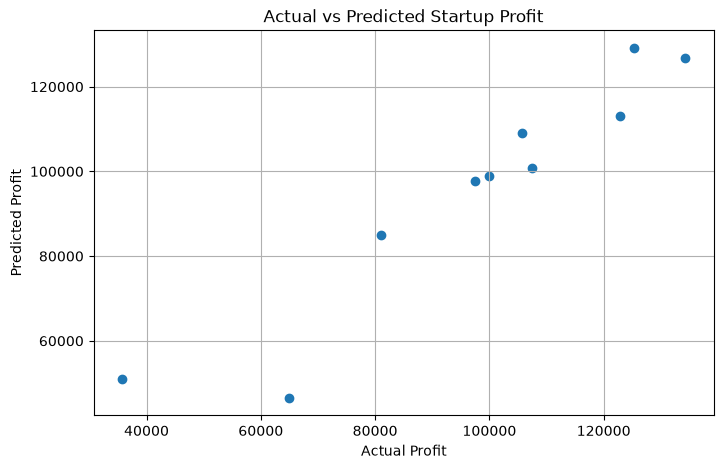

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")
plt.title("Actual vs Predicted Startup Profit")

plt.grid(True)
plt.show()

In [11]:
print("Regression Intercept:", model.intercept_)

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

print(coefficients)

Regression Intercept: 54071.875745990845
           Feature  Coefficient
0         RD_Spend     0.803779
1   Administration    -0.067929
2  Marketing_Spend     0.031242


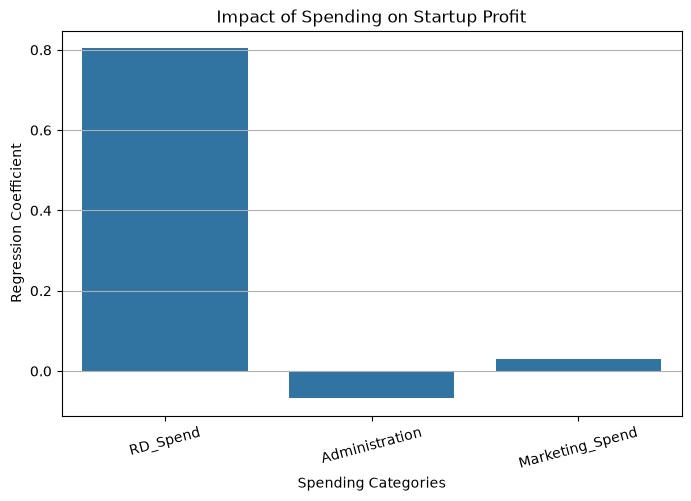

In [12]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=coefficients,
    x='Feature',
    y='Coefficient'
)

plt.title("Impact of Spending on Startup Profit")
plt.xlabel("Spending Categories")
plt.ylabel("Regression Coefficient")
plt.xticks(rotation=15)
plt.grid(axis='y')
plt.show()

In [13]:
new_data = pd.DataFrame({
    'RD_Spend': [21892.92, 23940.93],
    'Administration': [81910.77, 96489.63],
    'Marketing_Spend': [164270.7, 137001.1]
})

predictions = model.predict(new_data)

result = new_data.copy()
result['Predicted_Profit'] = predictions

print(result)

   RD_Spend  Administration  Marketing_Spend  Predicted_Profit
0  21892.92        81910.77         164270.7      71236.890791
1  23940.93        96489.63         137001.1      71040.764407


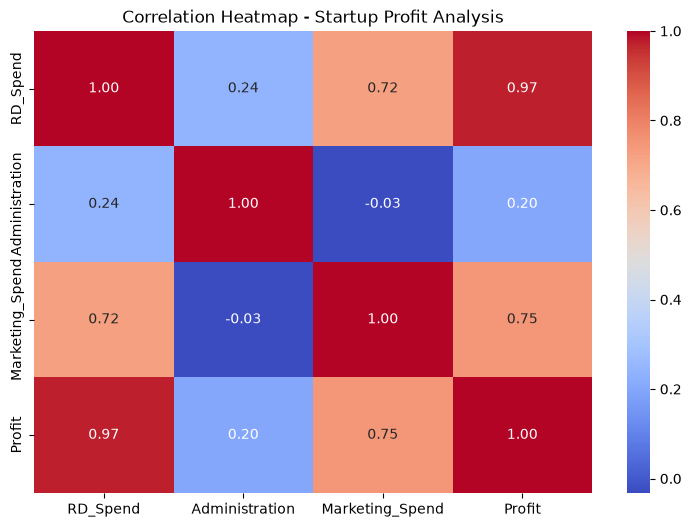

In [15]:
plt.figure(figsize=(9, 6))

correlation = df.select_dtypes(
    include='number'
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap - Startup Profit Analysis")
plt.show()

State
California    1766387.98
Florida       1900384.39
New York      1933859.59
Name: Profit, dtype: float64


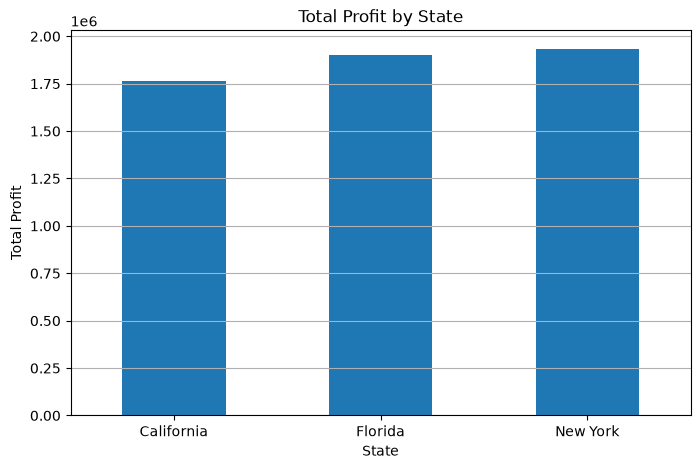

In [16]:
state_profit = df.groupby('State')['Profit'].sum()

print(state_profit)

plt.figure(figsize=(8, 5))

state_profit.plot(kind='bar')

plt.title("Total Profit by State")
plt.xlabel("State")
plt.ylabel("Total Profit")

plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

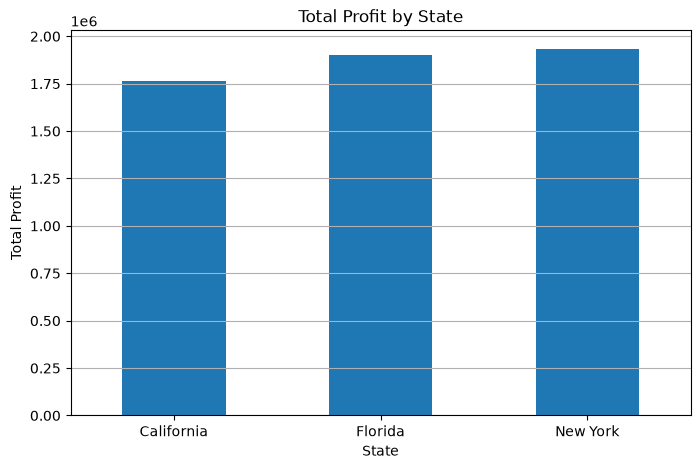

In [17]:
plt.figure(figsize=(8, 5))

state_profit.plot(kind='bar')

plt.title("Total Profit by State")
plt.xlabel("State")
plt.ylabel("Total Profit")

plt.xticks(rotation=0)
plt.grid(axis='y')

plt.savefig(
    "Profit_by_State.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
import os

print(os.path.exists("Profit_by_State.png"))
print(os.path.abspath("Profit_by_State.png"))

True
C:\Users\Rajesh\Profit_by_State.png
